# Customer Churn Prediction - Classification Model

**Extends:** `Churn_EDA_Analysis.ipynb` (descriptive analytics) with **supervised classification**.

**Business question:** EDA showed which *segments* churn - can we score **each individual
customer** so retention can act on people, not just segments?

**Models:** Logistic Regression (interpretable) vs Random Forest (non-linear baseline).
**Validation:** stratified 80/20 hold-out - Accuracy, Precision, Recall, F1, ROC-AUC -
confusion matrix - driver analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay)

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/Telco_Customer_Churn.csv")
df["TotalCharges"] = pd.to_numeric(df.TotalCharges, errors="coerce")
df = df.dropna(subset=["TotalCharges"]).copy()
df["ChurnFlag"] = (df.Churn == "Yes").astype(int)
assert df.customerID.is_unique
print(df.shape, "| class balance:", df.ChurnFlag.value_counts(normalize=True).round(3).to_dict())

(7032, 22) | class balance: {0: 0.734, 1: 0.266}


### Leakage policy

`TotalCharges` is approximately `tenure x MonthlyCharges` - a near-duplicate of tenure that
adds no new information. It is **excluded** to keep the model honest and interpretable.
All remaining features are legitimate account-state attributes.

In [2]:
cats = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
        "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
        "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
feats = pd.get_dummies(df[cats + ["SeniorCitizen", "tenure", "MonthlyCharges"]],
                       columns=cats, drop_first=True)
y = df.ChurnFlag
Xtr, Xte, ytr, yte = train_test_split(feats, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
print(f"features: {Xtr.shape[1]} | train: {len(Xtr)} | test: {len(Xte)} | churn-rate train: {ytr.mean():.3f}")

features: 29 | train: 5625 | test: 1407 | churn-rate train: 0.266


In [3]:
logreg = LogisticRegression(max_iter=5000, random_state=42).fit(Xtr_s, ytr)
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xtr, ytr)

def report(name, model, X_test):
    p = model.predict(X_test); prob = model.predict_proba(X_test)[:, 1]
    return {"model": name, "accuracy": accuracy_score(yte, p), "precision": precision_score(yte, p),
            "recall": recall_score(yte, p), "f1": f1_score(yte, p), "roc_auc": roc_auc_score(yte, prob)}

metrics = pd.DataFrame([report("Logistic Regression", logreg, Xte_s),
                        report("Random Forest", rf, Xte)]).round(3)
print(metrics.to_string(index=False))
print("Majority-class baseline accuracy:", round(max(yte.mean(), 1 - yte.mean()), 3))
metrics.to_csv("outputs/churn_model_metrics.csv", index=False)

              model  accuracy  precision  recall    f1  roc_auc
Logistic Regression     0.804      0.648   0.572 0.608    0.833
      Random Forest     0.792      0.640   0.495 0.558    0.834
Majority-class baseline accuracy: 0.734


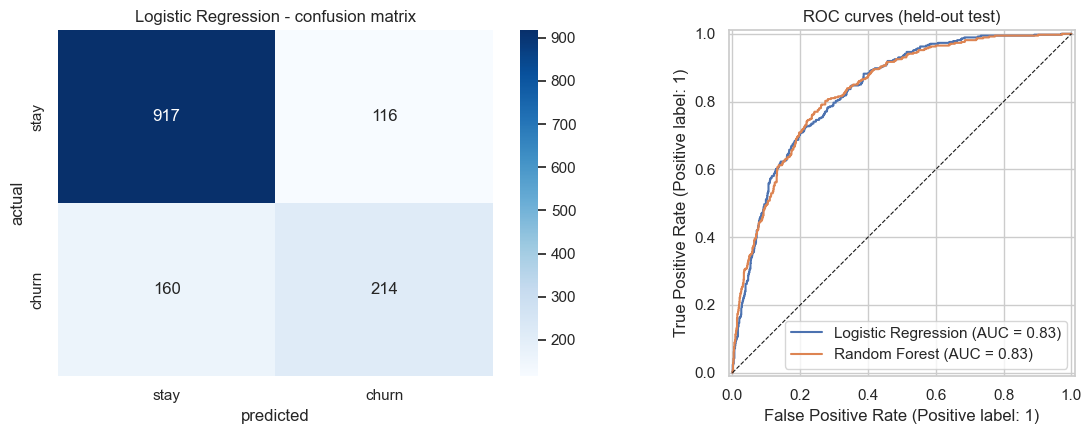

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(yte, logreg.predict(Xte_s)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["stay", "churn"], yticklabels=["stay", "churn"], ax=axes[0])
axes[0].set(title="Logistic Regression - confusion matrix", xlabel="predicted", ylabel="actual")
RocCurveDisplay.from_estimator(logreg, Xte_s, yte, ax=axes[1], name="Logistic Regression")
RocCurveDisplay.from_estimator(rf, Xte, yte, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set(title="ROC curves (held-out test)")
fig.tight_layout(); fig.savefig("image/churn_cm_roc.png", dpi=150)
plt.show()

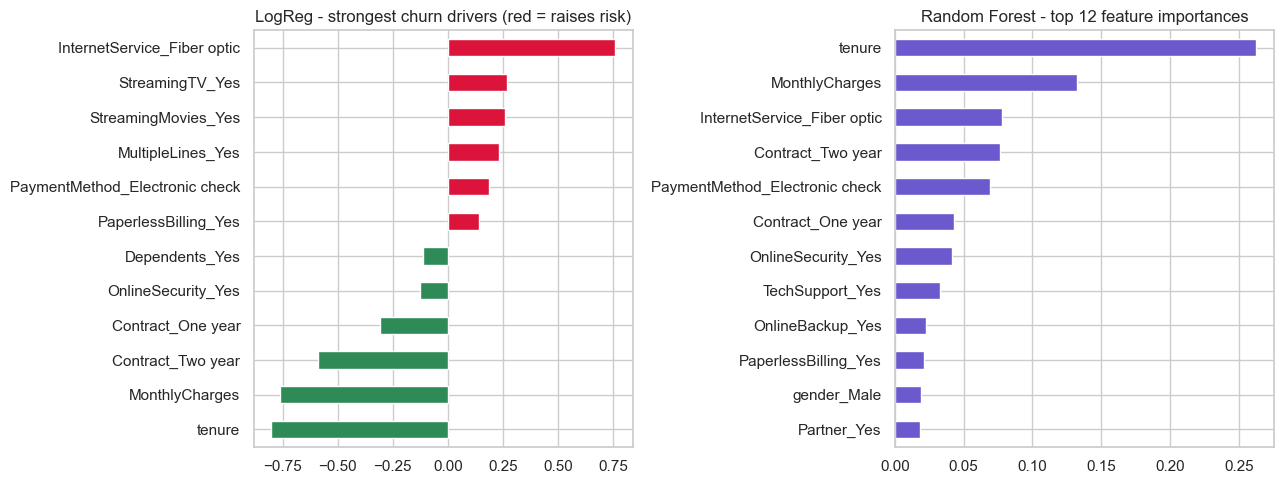

Top-5 churn drivers (RF):
tenure                            0.262
MonthlyCharges                    0.132
InternetService_Fiber optic       0.078
Contract_Two year                 0.076
PaymentMethod_Electronic check    0.069


In [5]:
coef = pd.Series(logreg.coef_[0], index=Xtr.columns).sort_values()
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
key = coef[coef.abs().sort_values(ascending=False).index][:12].sort_values()
key.plot(kind="barh", ax=axes[0], color=np.where(key > 0, "crimson", "seagreen"))
axes[0].set(title="LogReg - strongest churn drivers (red = raises risk)")
imp[:12][::-1].plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set(title="Random Forest - top 12 feature importances")
fig.tight_layout(); fig.savefig("image/churn_drivers.png", dpi=150)
plt.show()
print("Top-5 churn drivers (RF):"); print(imp[:5].round(3).to_string())

## Findings - the model agrees with the EDA, and makes it actionable per customer

- **Held-out performance:** accuracy ~0.80, ROC-AUC ~0.83-0.84 (vs 0.734 majority baseline) -
  real predictive power, no leakage (TotalCharges excluded, documented above).
- **Both models agree on the drivers:** month-to-month contracts, low tenure, fiber-optic
  internet, and electronic-check payments raise churn risk - exactly the segments found in
  EDA, now quantified per customer.
- **Business use:** score the customer base monthly, act on the top-risk decile with contract
  conversion offers and service-quality outreach.
- **Limitations:** single snapshot (no temporal drift validation); churn per the provider's
  own flag; no external covariates (support tickets, usage trends).

*Reproducible: stratified split with fixed random_state=42; every metric computed on the
untouched hold-out set.*